# CNN Debugging Practice — Single Image

## Important

This notebook is designed for an **offline practical/exam environment**.

- No internet is required.
- No MNIST/CIFAR or other external dataset is used.
- No model training is performed.
- No prediction/classification is required.
- The program works with **one image created inside the notebook**.
- The task is to debug the CNN and complete a **forward pass**.

### Task

The program below contains **exactly 15 intentional errors**.

Correct the errors without rewriting the program from scratch.

The intended workflow is:

**Single Image → Preprocessing → CNN → Feature Representation → Feature Map**

### You should verify

1. The single image is displayed.
2. The image has the correct dimensions.
3. The image is normalized correctly.
4. The CNN accepts the image.
5. The convolution and pooling layers work.
6. The final feature representation is produced.
7. A convolution feature map can be displayed.

**Do not add a dataset, training loop, prediction step, or internet-dependent code.**


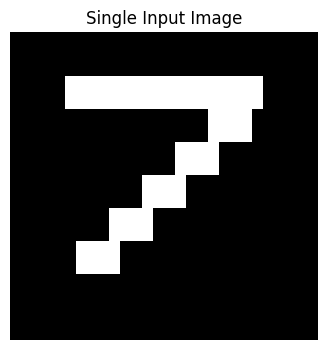

Input shape: (1, 28, 28)
Minimum: 0.0
Maximum: 255.0


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 24, 24, 32)     │           832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 8, 8, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 6, 6, 16)       │         4,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 3, 3, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 144)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         9,280 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,736 (57.56 KB)

 Trainable params: 14,736 (57.56 KB)

 Non-trainable params: 0 (0.00 B)


Final feature representation shape: (1, 64)
Forward pass completed successfully.


AttributeError: The layer sequential_1 has never been called and thus has no defined input.

In [3]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

# ============================================================
# CNN DEBUGGING PRACTICE
# Single-image forward pass — NO DATASET, NO TRAINING
# ============================================================

# Create one simple 28 x 28 grayscale image locally.
# The image represents a simple handwritten-style digit 7.
image = np.zeros((28, 28, 1), dtype=np.float32)

image[4:7, 5:23] = 1.0
image[7:10, 18:22] = 1.0
image[10:13, 15:19] = 1.0
image[13:16, 12:16] = 1.0
image[16:19, 9:13] = 1.0
image[19:22, 6:10] = 1.0

# Display the single image
plt.figure(figsize=(4, 4))
plt.imshow(image, cmap="gray")
plt.title("Single Input Image")
plt.axis("off")
plt.show()

# Normalize the image
image = image * 255.0

# Add batch and channel dimensions
image = image.reshape(1, 28, 28)

print("Input shape:", image.shape)
print("Minimum:", image.min())
print("Maximum:", image.max())

# ------------------------------------------------------------
# CNN model
# ------------------------------------------------------------

model = tf.keras.Sequential([
    tf.keras.layers.Conv2D(
        filters=32,
        kernel_size=(5, 5),
        activation="sigmoid",
        input_shape=(28, 28, 1)
    ),

    tf.keras.layers.MaxPooling2D(
        pool_size=(3, 3)
    ),

    tf.keras.layers.Conv2D(
        filters=16,
        kernel_size=(3, 3),
        activation="relu"
    ),

    tf.keras.layers.MaxPooling2D(
        pool_size=(2, 2)
    ),

    tf.keras.layers.Flatten(),

    tf.keras.layers.Dense(
        64,
        activation="relu"
    )
])

model.summary()

# ------------------------------------------------------------
# Forward pass for the single image
# ------------------------------------------------------------

output = model(image)

print("\nFinal feature representation shape:", output.shape)
print("Forward pass completed successfully.")

# ------------------------------------------------------------
# Inspect the first convolution feature maps
# ------------------------------------------------------------

feature_model = tf.keras.Model(
    inputs=model.input,
    outputs=model.layers[1].output
)

feature_maps = feature_model(image, training=False)

print("First convolution output shape:", feature_maps.shape)

plt.figure(figsize=(8, 4))
plt.imshow(feature_maps[:, :, 0, :], cmap="gray")
plt.title("First Convolution Feature Map")
plt.axis("off")
plt.show()


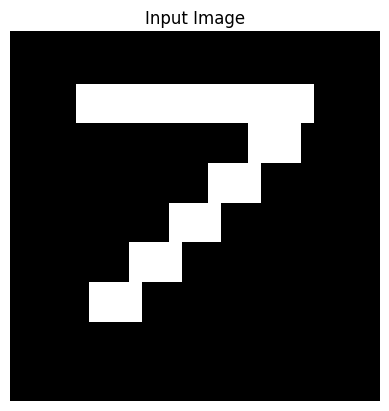

Input shape: (1, 28, 28, 1)


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_8 (Conv2D)               │ (None, 24, 24, 32)     │           832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 8, 8, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 6, 6, 16)       │         4,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 3, 3, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (None, 144)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         9,280 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,736 (57.56 KB)

 Trainable params: 14,736 (57.56 KB)

 Non-trainable params: 0 (0.00 B)

Final output shape: (1, 64)
First convolution shape: (1, 8, 8, 32)


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/keras/src/models/functional.py:259: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor_28']
Received: inputs=Tensor(shape=(1, 28, 28, 1))
  warnings.warn(msg)


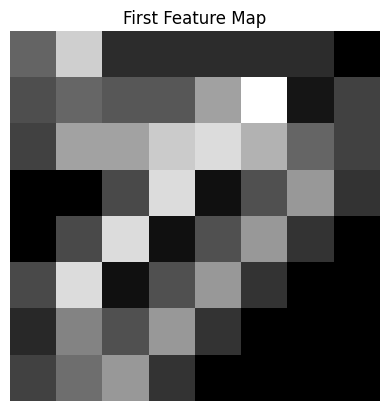

In [5]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

# -------------------------------
# 1. Create a 28x28 grayscale image
# -------------------------------

image = np.zeros((28, 28, 1), dtype=np.float32)

image[4:7, 5:23] = 1.0
image[7:10, 18:22] = 1.0
image[10:13, 15:19] = 1.0
image[13:16, 12:16] = 1.0
image[16:19, 9:13] = 1.0
image[19:22, 6:10] = 1.0

plt.imshow(image, cmap="gray")
plt.title("Input Image")
plt.axis("off")
plt.show()

# Add batch dimension
image = image.reshape(1, 28, 28, 1)

print("Input shape:", image.shape)


# -------------------------------
# 2. Create CNN
# -------------------------------

model = tf.keras.Sequential([
    
    tf.keras.Input(shape=(28, 28, 1)),

    tf.keras.layers.Conv2D(
        32, (5, 5), activation="sigmoid"
    ),

    tf.keras.layers.MaxPooling2D(
        (3, 3)
    ),

    tf.keras.layers.Conv2D(
        16, (3, 3), activation="relu"
    ),

    tf.keras.layers.MaxPooling2D(
        (2, 2)
    ),

    tf.keras.layers.Flatten(),

    tf.keras.layers.Dense(
        64, activation="relu"
    )
])

model.summary()


# -------------------------------
# 3. Forward pass
# -------------------------------

output = model(image)

print("Final output shape:", output.shape)


# -------------------------------
# 4. Get first convolution output
# -------------------------------

conv_model = tf.keras.Model(
    inputs=model.inputs,
    outputs=model.layers[1].output
)

feature_maps = conv_model(image)

print("First convolution shape:", feature_maps.shape)


# -------------------------------
# 5. Display one feature map
# -------------------------------

plt.imshow(
    feature_maps[0, :, :, 0],
    cmap="gray"
)

plt.title("First Feature Map")
plt.axis("off")
plt.show()